# Diabetes Prediction Using Machine Learning

## Project Overview

This project develops a machine learning system for predicting the likelihood of diabetes using patient health-related measurements.

Multiple classification algorithms are trained and evaluated using standard performance metrics. The models are compared using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

The best-performing model based on ROC-AUC is selected for the final prediction system.

## Objectives

- Load and understand the diabetes dataset.
- Perform data quality checks and preprocessing.
- Handle medically invalid zero values.
- Prepare training and testing datasets.
- Train multiple machine learning classification models.
- Compare model performance using multiple evaluation metrics.
- Analyze the confusion matrix and ROC curve.
- Identify important predictive features.
- Demonstrate diabetes prediction for a sample patient.

## Machine Learning Models

1. Logistic Regression
2. Random Forest
3. Gradient Boosting

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset Description

The dataset contains 768 patient records and 8 predictive health-related features.

### Input Features

- **Pregnancies** — Number of pregnancies
- **Glucose** — Plasma glucose concentration
- **BloodPressure** — Diastolic blood pressure
- **SkinThickness** — Triceps skin fold thickness
- **Insulin** — 2-Hour serum insulin
- **BMI** — Body Mass Index
- **DiabetesPedigreeFunction** — Diabetes pedigree function
- **Age** — Patient age

### Target Variable

**Outcome**

- `0` → No diabetes
- `1` → Diabetes

The dataset is used as a binary classification problem.

In [1]:
import sys
print(sys.executable)

c:\Users\Admin\Desktop\diabetes-prediction\venv\Scripts\python.exe


In [2]:
import pandas as pd

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv("diabetes.csv", names=columns)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (768, 9)

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Information")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())

print("\nData types:")
print(df.dtypes)

Dataset Information
Rows: 768
Columns: 9

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [4]:
import numpy as np

# Replace medically impossible zero values with NaN
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_columns] = df[zero_columns].replace(0, np.nan)

# Fill missing values using median
for column in zero_columns:
    df[column] = df[column].fillna(df[column].median())

# Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Data preprocessing completed successfully!")
print("Features:", X.shape)
print("Target:", y.shape)
print("\nRemaining missing values:", X.isnull().sum().sum())

Data preprocessing completed successfully!
Features: (768, 8)
Target: (768,)

Remaining missing values: 0


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data split and scaling completed successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Data split and scaling completed successfully!
Training samples: 614
Testing samples: 154


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    probabilities = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("Model training completed successfully!")

display(results_df.round(4))

Model training completed successfully!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
1,Random Forest,0.7403,0.6522,0.5556,0.6000,0.8161
2,Gradient Boosting,0.7532,0.6818,0.5556,0.6122,0.8300


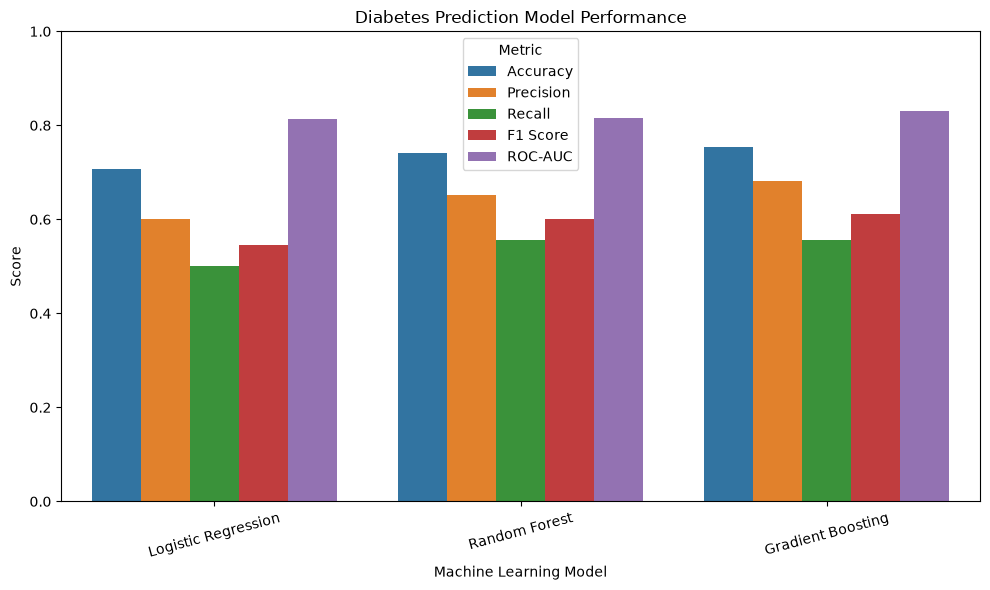

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Diabetes Prediction Model Performance")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=15)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [8]:
# Select the model with the highest ROC-AUC score
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Final Model Selected:")
print(best_model_name)

print("\nPerformance:")
display(
    results_df[
        results_df["Model"] == best_model_name
    ].round(4)
)

Final Model Selected:
Gradient Boosting

Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.7532,0.6818,0.5556,0.6122,0.83


In [9]:
from sklearn.metrics import classification_report, confusion_matrix

final_predictions = best_model.predict(X_test_scaled)

print("Classification Report - Gradient Boosting")
print("=" * 55)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Diabetes", "Diabetes"]
    )
)

Classification Report - Gradient Boosting
              precision    recall  f1-score   support

 No Diabetes       0.78      0.86      0.82       100
    Diabetes       0.68      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154



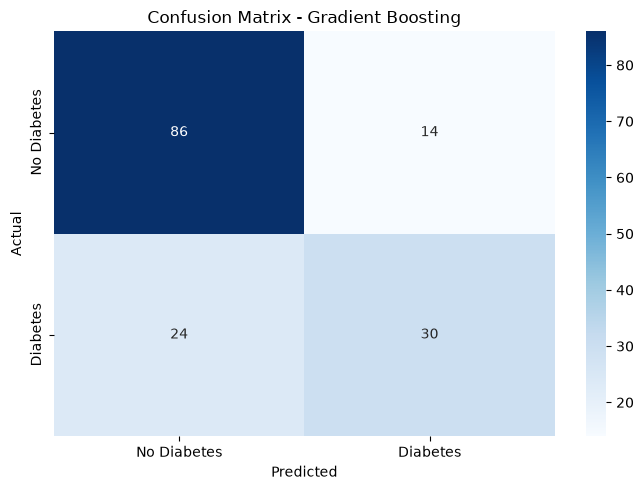

In [10]:
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

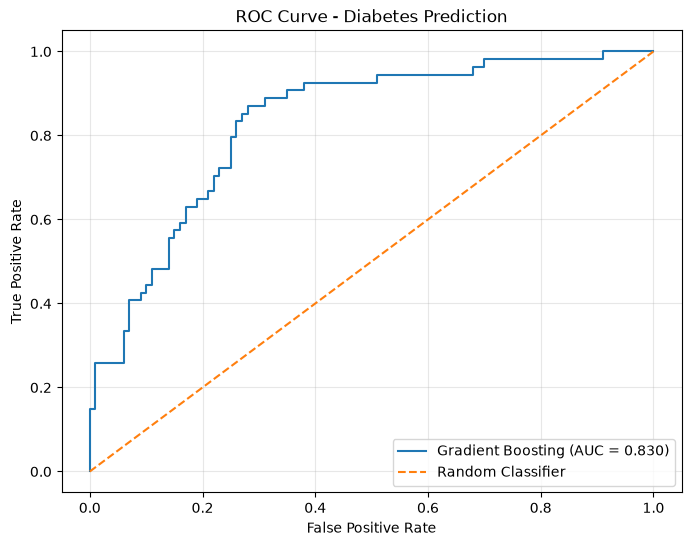

ROC-AUC Score: 0.83


In [11]:
from sklearn.metrics import roc_curve, auc

y_probability = best_model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_probability)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Gradient Boosting (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Diabetes Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

,Feature,Importance
1,Glucose,0.413105
5,BMI,0.193661
7,Age,0.116828
6,DiabetesPedigreeFunction,0.108774
4,Insulin,0.080017
0,Pregnancies,0.054101
3,SkinThickness,0.017741
2,BloodPressure,0.015773


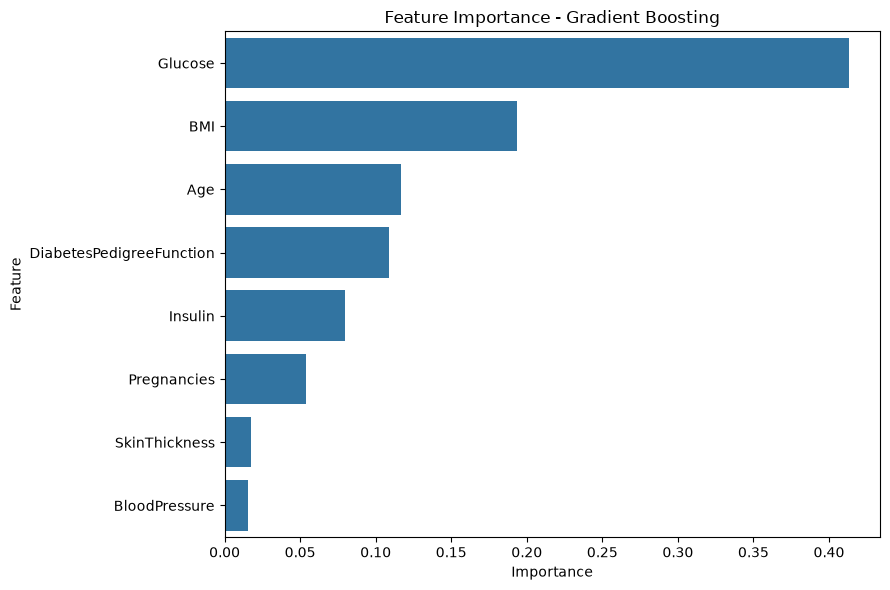

In [12]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [13]:
# Example patient data
sample_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 30,
    "Insulin": 100,
    "BMI": 32.0,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 35
}])

# Apply the same preprocessing used during training
sample_patient[zero_columns] = sample_patient[zero_columns].replace(0, np.nan)

for column in zero_columns:
    sample_patient[column] = sample_patient[column].fillna(
        df[column].median()
    )

sample_scaled = scaler.transform(sample_patient)

prediction = best_model.predict(sample_scaled)[0]
probability = best_model.predict_proba(sample_scaled)[0][1]

print("Diabetes Prediction")
print("=" * 40)
print("Prediction:", "Diabetes" if prediction == 1 else "No Diabetes")
print("Probability:", round(probability * 100, 2), "%")

Diabetes Prediction
Prediction: No Diabetes
Probability: 33.65 %


In [14]:
print("Statistical Summary")
print("=" * 50)

display(df.describe().round(2))

Statistical Summary


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,121.66,72.39,29.11,140.67,32.46,0.47,33.24,0.35
std,3.37,30.44,12.10,8.79,86.38,6.88,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.75,64.00,25.00,121.50,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,29.00,125.00,32.30,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


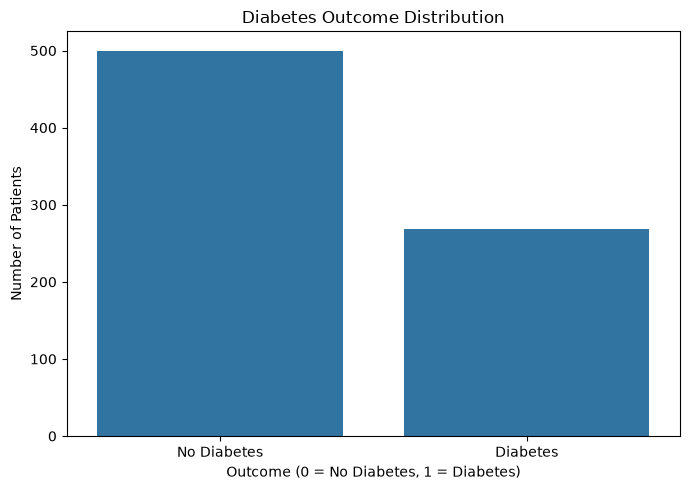

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Outcome"
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.tight_layout()
plt.show()

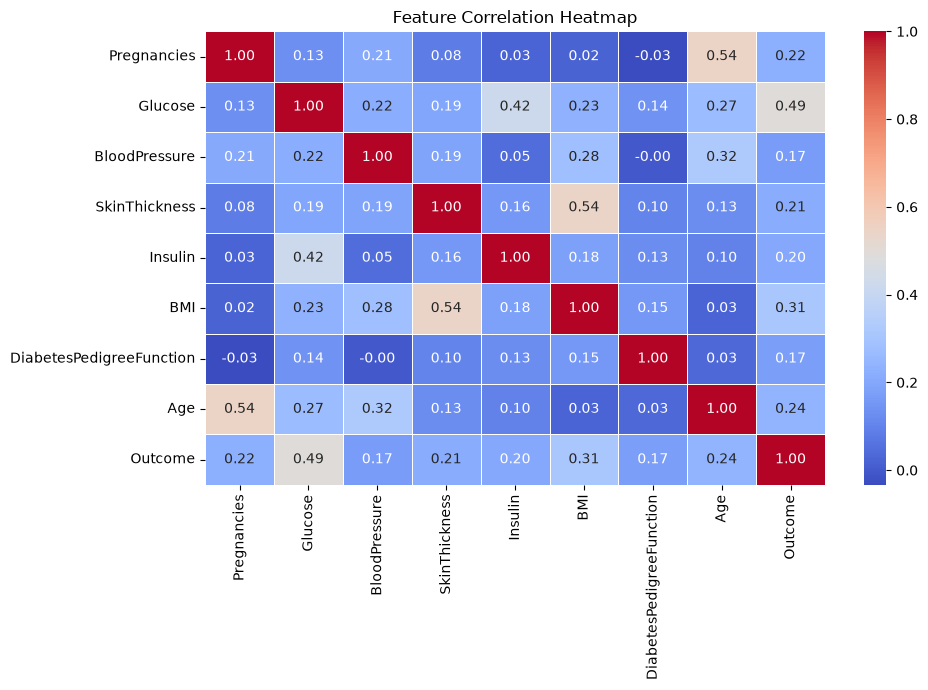

In [16]:
plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results")
print("=" * 50)

display(cv_df.round(4))

5-Fold Cross-Validation Results


,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.8428,0.0190
1,Random Forest,0.8222,0.0226
2,Gradient Boosting,0.8180,0.0175


# Conclusion

The Diabetes Prediction project successfully demonstrates the use of machine learning for binary classification of diabetes outcomes.

Three machine learning algorithms were implemented and evaluated:

- Logistic Regression
- Random Forest
- Gradient Boosting

The models were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. In addition, 5-fold stratified cross-validation was performed to provide a more reliable evaluation of model performance.

Gradient Boosting achieved the highest ROC-AUC score on the test-set comparison and was therefore selected as the final model for the sample prediction demonstrated in this project.

The project also includes:

- Data quality analysis
- Handling of medically invalid zero values
- Feature scaling
- Exploratory data analysis
- Correlation analysis
- Model comparison
- Confusion matrix
- ROC curve
- Feature importance analysis
- Sample patient prediction

Overall, the project demonstrates a complete machine learning workflow from data preprocessing through model evaluation and prediction.

**Note:** This model is an educational machine-learning demonstration and should not be used as a substitute for professional medical diagnosis.